# Datos Faltantes

In [4]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [6]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
183,0.045341,0.050680,-0.035307,0.063187,-0.004321,-0.001627,-0.010266,-0.002592,0.015568,0.056912,185.0
329,-0.012780,0.050680,-0.055785,-0.002228,-0.027712,-0.029184,0.019187,-0.039493,-0.017056,0.044485,135.0
44,0.045341,0.050680,0.068163,0.008101,-0.016704,0.004636,-0.076536,0.071210,0.032432,-0.017646,259.0
196,-0.023677,-0.044642,-0.046085,-0.033213,0.032830,0.036264,0.037595,-0.002592,-0.033246,0.011349,72.0
411,0.005383,-0.044642,0.058463,-0.043542,-0.073119,-0.072399,0.019187,-0.076395,-0.051404,-0.025930,136.0
339,0.027178,-0.044642,-0.007284,-0.050427,0.075484,0.056619,0.033914,-0.002592,0.043444,0.015491,95.0
62,-0.027310,0.050680,-0.007284,-0.040099,-0.011201,-0.013840,0.059685,-0.039493,-0.082379,-0.025930,52.0
364,0.001751,0.050680,-0.006206,-0.019442,-0.009825,0.004949,-0.039719,0.034309,0.014821,0.098333,262.0
387,-0.045472,-0.044642,0.015350,-0.074527,-0.049727,-0.017284,-0.028674,-0.002592,-0.104366,-0.075636,201.0
322,0.023546,0.050680,0.061696,0.062050,0.024574,-0.036073,-0.091262,0.155345,0.133397,0.081764,242.0


In [7]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [8]:
data.isnull().sum()

age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [9]:
imputer_media = SimpleImputer(strategy='mean')
data['bmi_imputado'] = imputer_media.fit_transform(data[['bmi']]).ravel()
data[['bmi', 'bmi_imputado']].head()

,bmi,bmi_imputado
0,0.061696,0.061696
1,-0.051474,-0.051474
2,0.044451,0.044451
3,-0.011595,-0.011595
4,-0.036385,-0.036385


### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [10]:
# Imputación con KNN
imputer_knn = KNNImputer(n_neighbors=5)

data[['bmi_knn', 'bp_knn']] = imputer_knn.fit_transform(data[['bmi', 'bp']])

# Comparación con imputación simple
print("Imputación simple (media) vs KNN:")
print(data[['bmi', 'bmi_imputado', 'bmi_knn', 'bp', 'bp_knn']].head(10))

Imputación simple (media) vs KNN:
        bmi  bmi_imputado   bmi_knn        bp    bp_knn
0  0.061696      0.061696  0.061696  0.021872  0.021872
1 -0.051474     -0.051474 -0.051474       NaN  0.003970
2  0.044451      0.044451  0.044451 -0.005670 -0.005670
3 -0.011595     -0.011595 -0.011595 -0.036656 -0.036656
4 -0.036385     -0.036385 -0.036385  0.021872  0.021872
5 -0.040696     -0.040696 -0.040696 -0.019442 -0.019442
6 -0.047163     -0.047163 -0.047163 -0.015999 -0.015999
7 -0.001895     -0.001895 -0.001895  0.066629  0.066629
8  0.061696      0.061696  0.061696 -0.040099 -0.040099
9       NaN     -0.000205 -0.021080 -0.033213 -0.033213


### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

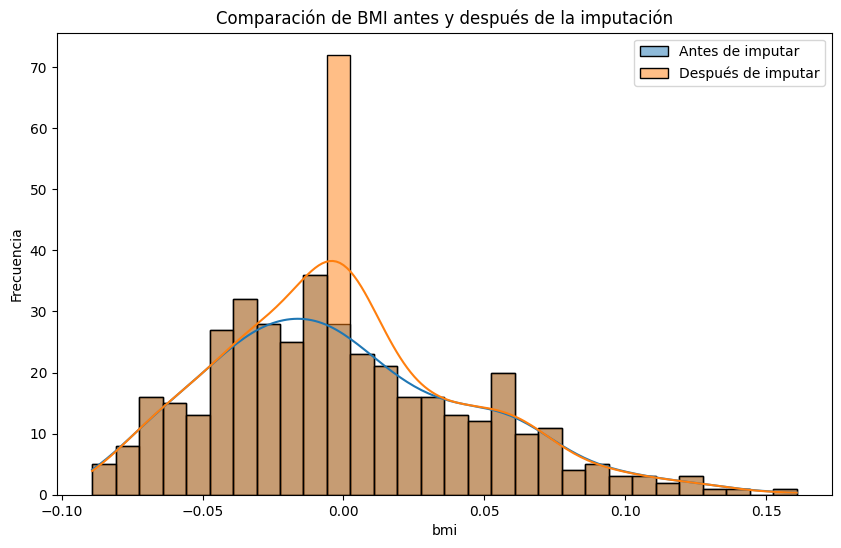

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.histplot(data['bmi'].dropna(), bins=30, kde=True, label='Antes de imputar')
sns.histplot(data['bmi_imputado'], bins=30, kde=True, label='Después de imputar')
plt.title('Comparación de BMI antes y después de la imputación')
plt.xlabel('bmi')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()